# Bilinear spectral regressor

In [1]:
from __future__ import annotations
import argparse
import json
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from concentration_split import grouped_concentration_split, regression_metrics


## Settings and paths

In [2]:
matplotlib.use('Agg')
PACKAGE = Path.cwd().parent
ROOT = PROJECT = PROJECT_ROOT = PACKAGE / 'work'
SETTINGS = argparse.Namespace(tag='double_ellipse_S843_theta205_D6p52_random10000_logC_m10p5_m8_t7200_dt60_allparam_noise0p05_spectrum0p01', 
                              split_seed=7, ranks='2', alphas='10', iterations=1, batch_size=256, normalizer_images=512, sections=8)


In [3]:
def parse_values(text: str, cast) -> list:
    return [cast(value.strip()) for value in text.split(',') if value.strip()]

In [4]:
def normalized_batch(images: np.ndarray, indices: np.ndarray, minimum: float, scale: float, mean_image: np.ndarray) -> np.ndarray:
    batch = np.asarray(images[indices], dtype=np.float32)
    batch = (batch - minimum) / scale
    return batch - mean_image

In [5]:
def make_features(images: np.ndarray, indices: np.ndarray, fixed_factor: np.ndarray, solve_for: str, minimum: float, scale: float, mean_image: np.ndarray, batch_size: int) -> np.ndarray:
    rank = fixed_factor.shape[1]
    free_axis = images.shape[1] if solve_for == 'wavelength' else images.shape[2]
    features = np.empty((len(indices), free_axis * rank), dtype=np.float32)
    for start in range(0, len(indices), batch_size):
        index = indices[start:start + batch_size]
        batch = normalized_batch(images, index, minimum, scale, mean_image)
        if solve_for == 'wavelength':
            compressed = np.einsum('nwt,tr->nwr', batch, fixed_factor, optimize=True)
        else:
            compressed = np.einsum('nwt,wr->ntr', batch, fixed_factor, optimize=True)
        features[start:start + len(index)] = compressed.reshape(len(index), -1)
    return features


In [6]:
def balance_factors(wavelength: np.ndarray, time: np.ndarray) -> None:
    for component in range(wavelength.shape[1]):
        wavelength_norm = np.linalg.norm(wavelength[:, component])
        time_norm = np.linalg.norm(time[:, component])
        if wavelength_norm > 0 and time_norm > 0:
            wavelength[:, component] *= np.sqrt(time_norm / wavelength_norm)
            time[:, component] *= np.sqrt(wavelength_norm / time_norm)


In [7]:
def predict(images: np.ndarray, indices: np.ndarray, wavelength: np.ndarray, time: np.ndarray, intercept: float, minimum: float, scale: float, mean_image: np.ndarray, batch_size: int) -> np.ndarray:
    result = np.empty(len(indices), dtype=np.float64)
    for start in range(0, len(indices), batch_size):
        index = indices[start:start + batch_size]
        batch = normalized_batch(images, index, minimum, scale, mean_image)
        result[start:start + len(index)] = intercept + np.einsum('nwt,wr,tr->n', batch, wavelength, time, optimize=True)
    return result


In [8]:
args = SETTINGS
data = PROJECT / ('langmuir_spectral_images_' + args.tag)
out = ROOT / 'models' / ('bilinear_spectral_' + args.tag)
figures = ROOT / 'figures' / ('bilinear_spectral_' + args.tag)
out.mkdir(parents=True, exist_ok=True)
figures.mkdir(parents=True, exist_ok=True)
metadata = pd.read_csv(data / 'spectral_image_metadata.csv')
images = np.load(data / 'spectral_images.npy', mmap_mode='r')

if images.shape[0] != len(metadata):
    raise ValueError(f"Image count ({images.shape[0]}) must match metadata rows ({len(metadata)}).")
target_log10 = np.log10(metadata.concentrationM.to_numpy(dtype=np.float64))
split_args = argparse.Namespace(split_seed=args.split_seed, test_fraction=0.15, val_fraction=0.15)
splits = grouped_concentration_split(metadata, split_args)

train_indices = splits.train
seed = args.split_seed
sample_size = args.normalizer_images
batch_size = args.batch_size
rng = np.random.default_rng(seed)
sample = train_indices

if len(sample) > sample_size:
    sample = rng.choice(sample, size=sample_size, replace=False)

sampled = np.asarray(images[sample], dtype=np.float32)
minimum = float(sampled.min())
maximum = float(sampled.max())
scale = maximum - minimum
mean_image = np.zeros(images.shape[1:], dtype=np.float64)


In [9]:
for start in range(0, len(train_indices), batch_size):
    index = train_indices[start:start + batch_size]
    batch = (np.asarray(images[index], dtype=np.float32) - minimum) / scale
    mean_image += batch.sum(axis=0, dtype=np.float64)

mean_image = (mean_image / len(train_indices)).astype(np.float32)
minimum, scale, mean_image = (minimum, scale, mean_image)
intercept = float(target_log10[splits.train].mean())
centered_train_target = target_log10[splits.train] - intercept
rows: list[dict[str, float | int]] = []
best: dict | None = None

In [ ]:
for rank in parse_values(args.ranks, int):
    train_indices = splits.train
    centered_target = centered_train_target
    batch_size = args.batch_size
    cross_covariance = np.zeros(images.shape[1:], dtype=np.float64)

    for start in range(0, len(train_indices), batch_size):
        index = train_indices[start:start + batch_size]
        batch = normalized_batch(images, index, minimum, scale, mean_image)
        batch_target = centered_target[start:start + len(index)]
        cross_covariance += np.einsum('n,nwt->wt', batch_target, batch, optimize=True)

    cross_covariance /= len(train_indices)
    left, singular, right_t = np.linalg.svd(cross_covariance, full_matrices=False)
    root = np.sqrt(np.maximum(singular[:rank], 1e-12))
    initial_wavelength, initial_time = ((left[:, :rank] * root).astype(np.float64), (right_t[:rank].T * root).astype(np.float64))

    for alpha in parse_values(args.alphas, float):
        wavelength = initial_wavelength.copy()
        time = initial_time.copy()
        best_for_setting: dict | None = None
        for iteration in range(1, args.iterations + 1):
            wavelength_features = make_features(images, splits.train, time, 'wavelength', minimum, scale, mean_image, args.batch_size)
            wavelength = Ridge(alpha=alpha, fit_intercept=False, solver='lsqr', tol=1e-06).fit(wavelength_features, centered_train_target).coef_.reshape(images.shape[1], rank)
            balance_factors(wavelength, time)
            time_features = make_features(images, splits.train, wavelength, 'time', minimum, scale, mean_image, args.batch_size)
            time = Ridge(alpha=alpha, fit_intercept=False, solver='lsqr', tol=1e-06).fit(time_features, centered_train_target).coef_.reshape(images.shape[2], rank)
            balance_factors(wavelength, time)
            validation_prediction = predict(images, splits.val, wavelength, time, intercept, minimum, scale, mean_image, args.batch_size)
            validation_rmse = float(np.sqrt(np.mean((validation_prediction - target_log10[splits.val]) ** 2)))
            row = {'rank': rank, 'alpha': alpha, 'iteration': iteration, 'validation_rmse_log10': validation_rmse}
            rows.append(row)
            print(json.dumps(row), flush=True)
            if best_for_setting is None or validation_rmse < best_for_setting['validation_rmse']:
                best_for_setting = {'rank': rank, 'alpha': alpha, 'iteration': iteration, 'validation_rmse': validation_rmse, 'wavelength': wavelength.copy(), 'time': time.copy()}
        if best is None or best_for_setting['validation_rmse'] < best['validation_rmse']:
            best = best_for_setting


In [ ]:
test_prediction = predict(images, splits.test, best['wavelength'], best['time'], intercept, minimum, scale, mean_image, args.batch_size)
metrics = regression_metrics(target_log10[splits.test], test_prediction)
test = pd.DataFrame({'recordId': metadata.recordId.to_numpy()[splits.test], 'concentrationM': metadata.concentrationM.to_numpy()[splits.test], 'true_log10_concentration': target_log10[splits.test], 'pred_log10_concentration': test_prediction, 'pred_concentrationM': 10.0 ** test_prediction})
test.to_csv(out / 'test_predictions.csv', index=False)

pd.DataFrame(rows).to_csv(out / 'validation_search.csv', index=False)
pd.DataFrame([{'method': 'Bilinear spectral regression', 'n_test': len(test), 'rank': best['rank'], 'alpha': best['alpha'], 'iteration': best['iteration'], **metrics}]).to_csv(out / 'test_metrics.csv', index=False)
np.savez_compressed(out / 'model_factors.npz', wavelength_factor=best['wavelength'], time_factor=best['time'], intercept=intercept, input_min=minimum, input_scale=scale, mean_image=mean_image)

edges = np.linspace(-10.5, -8.0, args.sections + 1)
section_rows = []
for section in range(args.sections):
    mask = (test.true_log10_concentration >= edges[section]) & (test.true_log10_concentration <= edges[section + 1] if section == args.sections - 1 else test.true_log10_concentration < edges[section + 1])
    error = (test.loc[mask, 'pred_log10_concentration'] - test.loc[mask, 'true_log10_concentration']).to_numpy()
    section_rows.append({'section': section + 1, 'log10_lower_M': edges[section], 'log10_upper_M': edges[section + 1], 'n_test': int(mask.sum()), 'rmse_log10_concentration': float(np.sqrt(np.mean(error ** 2))), 'mae_log10_concentration': float(np.mean(np.abs(error))), 'bias_log10_concentration': float(np.mean(error))})
pd.DataFrame(section_rows).to_csv(out / 'rmse_by_concentration_section.csv', index=False)

summary = {'model': 'Low-rank bilinear spectral regression: y = intercept + sum_r a_r.T X b_r', 'selection': 'Rank, factor Ridge alpha, and ALS iteration selected by validation RMSE', 'input_shape': list(images.shape), 'selected_rank': best['rank'], 'selected_alpha': best['alpha'], 'selected_iteration': best['iteration'], 'n_parameters_excluding_intercept': int(best['rank'] * (images.shape[1] + images.shape[2])), 'split': {'seed': args.split_seed, 'n_train': len(splits.train), 'n_validation': len(splits.val), 'n_test': len(splits.test)}, 'metrics': metrics}
(out / 'experiment_summary.json').write_text(json.dumps(summary, indent=2))


{
  "model": "Low-rank bilinear spectral regression: y = intercept + sum_r a_r.T X b_r",
  "selection": "Rank, factor Ridge alpha, and ALS iteration selected by validation RMSE",
  "input_shape": [
    10000,
    351,
    121
  ],
  "selected_rank": 2,
  "selected_alpha": 10.0,
  "selected_iteration": 1,
  "n_parameters_excluding_intercept": 944,
  "split": {
    "seed": 7,
    "n_train": 7000,
    "n_validation": 1500,
    "n_test": 1500
  },
  "metrics": {
    "rmse_log10_concentration": 0.09137055096314944,
    "mae_log10_concentration": 0.06075921710063572,
    "r2_log10_concentration": 0.984141500850358,
    "pearson_corr": 0.9920594403450522,
    "spearman_corr": 0.9928459630426503,
    "median_fold_error": 1.083265334617291,
    "p90_fold_error": 1.4315677680737733
  }
}


{
  "model": "Low-rank bilinear spectral regression: y = intercept + sum_r a_r.T X b_r",
  "selection": "Rank, factor Ridge alpha, and ALS iteration selected by validation RMSE",
  "input_shape": [
    10000,
    351,
    121
  ],
  "selected_rank": 2,
  "selected_alpha": 10.0,
  "selected_iteration": 1,
  "n_parameters_excluding_intercept": 944,
  "split": {
    "seed": 7,
    "n_train": 7000,
    "n_validation": 1500,
    "n_test": 1500
  },
  "metrics": {
    "rmse_log10_concentration": 0.09137055096314944,
    "mae_log10_concentration": 0.06075921710063572,
    "r2_log10_concentration": 0.984141500850358,
    "pearson_corr": 0.9920594403450522,
    "spearman_corr": 0.9928459630426503,
    "median_fold_error": 1.083265334617291,
    "p90_fold_error": 1.4315677680737733
  }
}


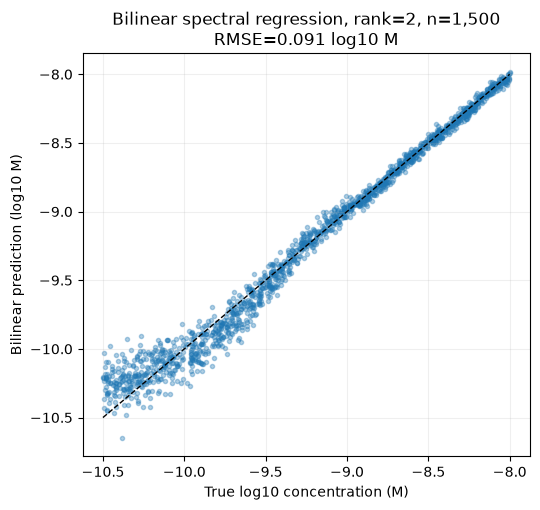

In [14]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(5.5, 5.2))
ax.scatter(test.true_log10_concentration, test.pred_log10_concentration, s=9, alpha=0.35)
ax.plot([-10.5, -8.0], [-10.5, -8.0], 'k--', linewidth=1)
ax.set(xlabel='True log10 concentration (M)', ylabel='Bilinear prediction (log10 M)', title=f"Bilinear spectral regression, rank={best['rank']}, n={len(test):,}\nRMSE={metrics['rmse_log10_concentration']:.3f} log10 M")
ax.grid(alpha=0.2)
fig.tight_layout()
#fig.savefig(figures / 'test_prediction_vs_truth.png', dpi=200)
#plt.close(fig)
print(json.dumps(summary, indent=2), flush=True)
